In [ ]:
# CELL 1 — Install & Import Libraries

# ==============================
# 📦 Install required libraries
# ==============================
!pip install pandas numpy matplotlib scikit-learn tensorflow seaborn --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
# CELL 2 — Upload Earthquake Dataset

from google.colab import files
uploaded = files.upload()


Saving earthquake_dataset.csv to earthquake_dataset.csv


In [ ]:
# CELL 3 — Load & Inspect Data

df = pd.read_csv("earthquake_dataset.csv")

# Convert timestamp
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df = df.dropna(subset=['timestamp'])

# Sort for time-series (CRITICAL)
df = df.sort_values('timestamp')

df.tail()


,timestamp,motion,vibration_detected,earthquake_detected,risk_level
2349,2026-01-29 21:27:37,0.025,Yes,No,Medium
2350,2026-01-29 21:27:41,0.025,Yes,No,Medium
2351,2026-01-29 21:27:46,0.027,Yes,No,Medium
2352,2026-01-29 21:27:51,0.024,Yes,No,Medium
2353,2026-01-29 21:27:55,0.024,Yes,No,Medium


In [ ]:
# CELL 4 — Encode Labels & Select Features

# Convert vibration to numeric
df['vibration_detected'] = df['vibration_detected'].map({'Yes':1, 'No':0})

# Map risk_level to intensity (0=Low, 1=Medium, 2=High)
df['intensity'] = df['risk_level'].map({
    'Low': 0,
    'Medium': 1,
    'High': 2,
    'Critical': 2   # merge High + Critical
})

features = ['motion', 'vibration_detected']
X_data = df[features]
y_data = df['intensity']

X_data.describe()


,motion,vibration_detected
count,2339.000000,2339.000000
mean,0.191670,0.644292
std,0.450226,0.478830
min,0.000000,0.000000
25%,0.020000,0.000000
50%,0.026000,1.000000
75%,0.036000,1.000000
max,2.464000,1.000000


In [ ]:
# CELL 5 — Normalize Features

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_data)


In [ ]:
# CELL 6 — Create Time-Series Sequences (LSTM Input)

SEQUENCE_LENGTH = 15   # ~45 seconds (ESP32 delay=3s)

X = []
y = []

for i in range(SEQUENCE_LENGTH, len(X_scaled)):
    X.append(X_scaled[i-SEQUENCE_LENGTH:i])
    y.append(y_data.iloc[i])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (2324, 15, 2)
y shape: (2324,)


In [ ]:
# CELL 7 — Train / Test Split (NO SHUFFLE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=False
)


In [ ]:
# CELL 8 — Build LSTM Classification Model

model = Sequential([
    LSTM(
        32,
        input_shape=(X.shape[1], X.shape[2]),
        return_sequences=False,
        unroll=True
    ),
    Dropout(0.2),
    Dense(3, activation='softmax')   # Multi-class EARTHQUAKE DETECTION (Intensity)
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,579 (17.89 KB)

 Trainable params: 4,579 (17.89 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# CELL 9 — Train Model

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=40,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stop]
)


Epoch 1/40
59/59 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.2875 - loss: 1.0748 - val_accuracy: 0.8946 - val_loss: 0.5298
Epoch 2/40
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7634 - loss: 0.6757 - val_accuracy: 0.8882 - val_loss: 0.4880
Epoch 3/40
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7496 - loss: 0.5861 - val_accuracy: 0.8860 - val_loss: 0.3508
Epoch 4/40
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7780 - loss: 0.5186 - val_accuracy: 0.9032 - val_loss: 0.3071
Epoch 5/40
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7893 - loss: 0.4993 - val_accuracy: 0.9118 - val_loss: 0.3171
Epoch 6/40
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7978 - loss: 0.4591 - val_accuracy: 0.9161 - val_loss: 0.3067
Epoch 7/40
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7924 - loss: 0.4557 - val_accuracy: 0.9140 - val_loss: 0.3511
Epoch 8/40
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8085 - loss: 0.4435 - val_accuracy: 0.9204 - val_loss:

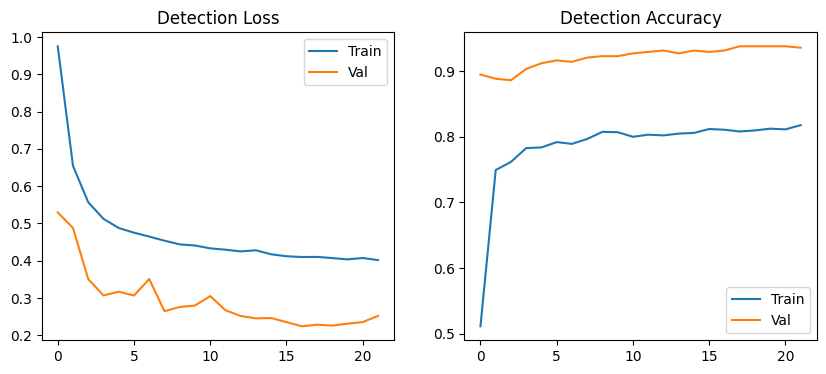

In [ ]:
# CELL 10 — Training Loss & Accuracy Plot

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Detection Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Detection Accuracy")
plt.legend()

plt.show()


In [ ]:
# CELL 11 — Predictions

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)


15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


In [ ]:
# CELL 12 — ✅ Accuracy Score

acc = accuracy_score(y_test, y_pred)
print("✅ Earthquake Detection Accuracy:", round(acc * 100, 2), "%")


✅ Earthquake Detection Accuracy: 93.12 %


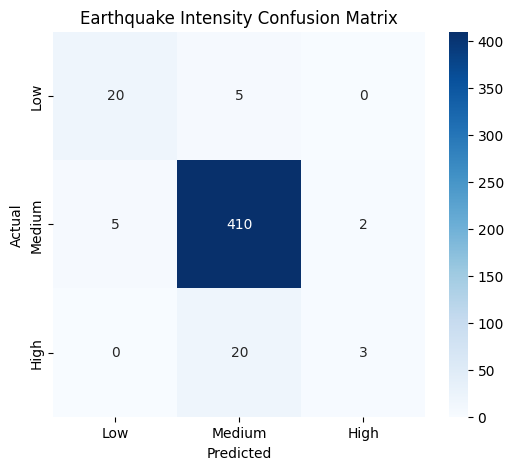

In [ ]:
# CELL 13 — 📈 Confusion Matrix (3 Classes)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low","Medium","High"],
    yticklabels=["Low","Medium","High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Earthquake Intensity Confusion Matrix")
plt.show()


In [ ]:
# CELL 14 — Classification Report


print("Earthquake Detection Classification Report")

print(classification_report(
    y_test,
    y_pred,
    labels=[0,1,2],
    target_names=["Low","Medium","High"],
    zero_division=0
))


Earthquake Detection Classification Report
              precision    recall  f1-score   support

         Low       0.80      0.80      0.80        25
      Medium       0.94      0.98      0.96       417
        High       0.60      0.13      0.21        23

    accuracy                           0.93       465
   macro avg       0.78      0.64      0.66       465
weighted avg       0.92      0.93      0.92       465



In [ ]:
# CELL 15 — Save Model

model.save("earthquake_detection_lstm_model.keras")
print("✅ Earthquake Detection LSTM model saved")


✅ Earthquake Detection LSTM model saved


In [ ]:
# CELL 16 — Convert to PURE TFLite (Flutter Compatible)

import tensorflow as tf

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
converter._experimental_lower_tensor_list_ops = True
converter.experimental_enable_resource_variables = False
converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

with open("earthquake_intensity_lstm_model.tflite", "wb") as f:
    f.write(tflite_model)

print("✅ Earthquake Intensity TFLite model created")


Saved artifact at '/tmp/tmpc7mq62yi'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 15, 2), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  136224032573968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136224032574352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136224032575504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136224032575696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136226349245712: TensorSpec(shape=(), dtype=tf.resource, name=None)
✅ Earthquake Intensity TFLite model created


In [ ]:
# CELL 17 — Download TFLite Model

from google.colab import files
files.download("earthquake_intensity_lstm_model.tflite")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>